# Lab 8 - Extraction and Comparison of MFCC, PLP, LPCC and GFCC Features from Speech Signals

**Topic:** load and preprocess a speech signal, frame and window it, extract the four classic
feature sets for speech recognition - **MFCC**, **PLP** (perceptual linear prediction),
**LPCC** (LPC cepstral coefficients) and **GFCC** (gammatone frequency cepstral coefficients) -
visualise them, and analyse their suitability for speech recognition with a noise-robustness
experiment.

**Sections (following the lab sheet)**
1. Load and preprocess a speech signal
2. Framing and windowing
3. MFCC features
4. PLP features (perceptual auditory processing)
5. LPC coefficients and LPCC features
6. GFCC features (gammatone filterbank)
7. Visualisation and comparison
8. Suitability for speech-recognition applications

**Kernel:** Speech Lab (.venv)

Every extractor is implemented from scratch with NumPy/SciPy in
`lab 8/solution/feature_extraction.py` and imported here - the script is not modified.
Figures and CSVs produced by this notebook are written to `notebooks/lab8_outputs/`.

## Setup

The notebook analyses a **3-second segment (1.0-4.0 s) of `harvard.wav`** (real speech, taken from
Lab 1's solution folder). If that file is missing, the module falls back to a built-in synthetic
`/a-i-u/` utterance, so everything still runs offline. Audio, figures and tables are all written to
`notebooks/lab8_outputs/`.

In [1]:
%matplotlib inline
import os, sys, csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Audio

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "lab 8" / "solution").exists())
SOL = ROOT / "lab 8" / "solution"
assert SOL.exists(), SOL
OUT_DIR = ROOT / "notebooks" / "lab8_outputs"        # notebook figures/CSVs go here
OUT_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SOL))

import feature_extraction as fx                       # the Lab 8 solution module

WAV = ROOT / "lab 1" / "solution" / "POS, parser and BOW" / "1) POS, parser and BoW" / "harvard.wav"
START, DURATION = 1.0, 3.0                            # segment used throughout the notebook
FREQS = np.fft.rfftfreq(fx.N_FFT, 1 / fx.SR)         # FFT bin frequencies (Hz)


def html_table(headers, rows, digits=3):
    """Small HTML table helper (pandas is not installed in the Speech Lab venv)."""
    def cell(x):
        if isinstance(x, float):
            return "n/a" if x != x else f"{x:.{digits}f}"
        if isinstance(x, int):
            return f"{x:,}"
        return str(x)
    head = "".join(f"<th style='text-align:left;padding:2px 8px'>{h}</th>" for h in headers)
    body = "".join(
        "<tr>" + "".join(f"<td style='text-align:left;padding:2px 8px'>{cell(x)}</td>" for x in r) + "</tr>"
        for r in rows)
    return HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>")


print(f"python {sys.version.split()[0]} | numpy {np.__version__}")
print(f"repo  : {ROOT}")
print(f"audio : {WAV}  ({'found' if WAV.exists() else 'missing - synthetic fallback'})")

python 3.13.12 | numpy 2.5.3
repo  : U:\VITc\speech lab
audio : U:\VITc\speech lab\lab 1\solution\POS, parser and BOW\1) POS, parser and BoW\harvard.wav  (found)


## Task 1 - Load and preprocess the speech signal

`harvard.wav` is 44.1 kHz stereo; the module makes it **mono**, **resamples to 16 kHz**
(`scipy.signal.resample_poly`), cuts the segment, applies **pre-emphasis**
`y[n] = x[n] - 0.97 x[n-1]` (boosts the high frequencies that carry consonant information),
removes DC and normalises the peak.

U:\VITc\speech lab\lab 8\solution\feature_extraction.py:126: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sr, data = wavfile.read(path)


source        : harvard.wav [1.0-4.0s], mono 16000 Hz
sample rate   : 16000 Hz
length        : 48000 samples (3.00 s)
pre-processing: mono -> resample 44.1k -> 16k -> segment [1.0, 4.0] s
                -> pre-emphasis (0.97) -> DC removal -> peak normalisation
RMS / peak    : 0.0595 / 0.9500


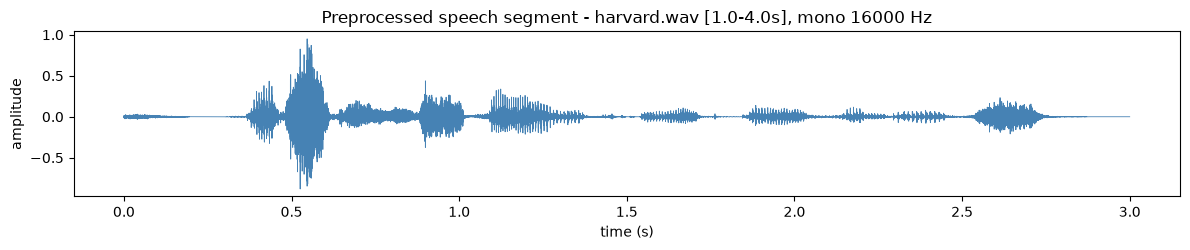

Play the analysed segment:


In [2]:
sig, sr, source = fx.load_speech(str(WAV) if WAV.exists() else None, start=START, duration=DURATION)
print(f"source        : {source}")
print(f"sample rate   : {sr} Hz")
print(f"length        : {len(sig)} samples ({len(sig) / sr:.2f} s)")
print(f"pre-processing: mono -> resample 44.1k -> 16k -> segment [{START}, {START + DURATION}] s")
print(f"                -> pre-emphasis (0.97) -> DC removal -> peak normalisation")
print(f"RMS / peak    : {np.sqrt(np.mean(sig ** 2)):.4f} / {np.abs(sig).max():.4f}")

fig, ax = plt.subplots(figsize=(12, 2.6))
ax.plot(np.arange(len(sig)) / sr, sig, lw=0.6, color="steelblue")
ax.set(xlabel="time (s)", ylabel="amplitude", title=f"Preprocessed speech segment - {source}")
fig.tight_layout()
fig.savefig(OUT_DIR / "waveform.png", dpi=130)
plt.show()

from scipy.io import wavfile
wavfile.write(str(OUT_DIR / "lab7_segment.wav"), sr, (sig / np.abs(sig).max() * 32767).astype(np.int16))
print("Play the analysed segment:")
display(Audio(str(OUT_DIR / "lab7_segment.wav")))

## Task 2 - Framing and windowing

A speech signal is slowly time-varying, so it is analysed in short **25 ms frames** (400 samples at
16 kHz) with a **10 ms hop** (75 % overlap). Each frame is multiplied by a **Hamming window**
`w[n] = 0.54 - 0.46 cos(2*pi*n/(N-1))` to taper the edges and reduce spectral leakage before the FFT.
The frame matrix has shape `(n_frames, 400)`.

frame length: 400 samples (25 ms)
hop size    : 160 samples (10 ms)
frames      : 298  -> frame matrix (298, 400)
Hamming     : first/last/centre = 0.080 / 0.080 / 1.000


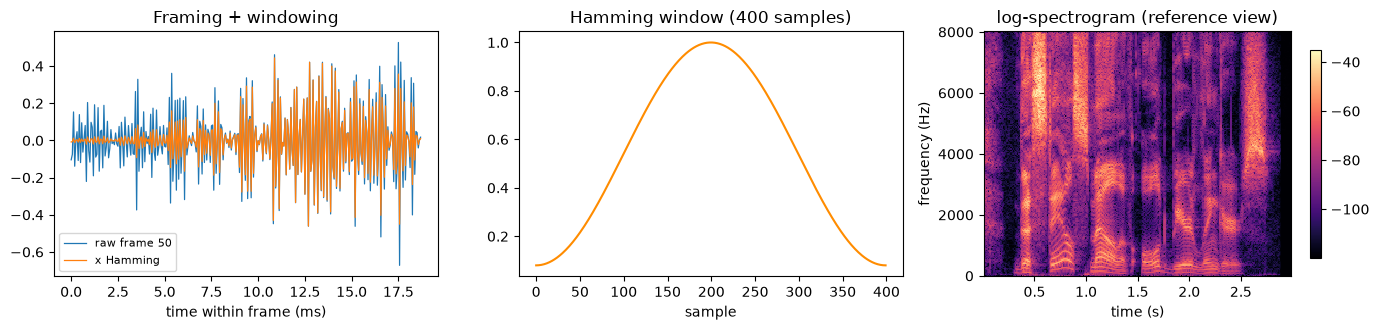

In [3]:
frames = fx.frame_signal(sig, sr)
win = fx.hamming_window(frames.shape[1])
hop = int(sr * fx.HOP_MS / 1000)
print(f"frame length: {frames.shape[1]} samples ({fx.FRAME_MS:.0f} ms)")
print(f"hop size    : {hop} samples ({fx.HOP_MS:.0f} ms)")
print(f"frames      : {frames.shape[0]}  -> frame matrix {frames.shape}")
print(f"Hamming     : first/last/centre = {win[0]:.3f} / {win[-1]:.3f} / {win[len(win)//2]:.3f}")

from scipy.signal import spectrogram
f_spec, t_spec, sxx = spectrogram(sig, sr, nperseg=frames.shape[1], noverlap=frames.shape[1] - hop)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
axes[0].plot(np.arange(300) / sr * 1000, frames[50][:300], lw=0.9, label="raw frame 50")
axes[0].plot(np.arange(300) / sr * 1000, (frames[50] * win)[:300], lw=0.9, label="x Hamming")
axes[0].set(xlabel="time within frame (ms)", title="Framing + windowing")
axes[0].legend(fontsize=8)
axes[1].plot(win, color="darkorange")
axes[1].set(xlabel="sample", title=f"Hamming window ({frames.shape[1]} samples)")
im = axes[2].pcolormesh(t_spec, f_spec, 10 * np.log10(sxx + 1e-12), shading="auto", cmap="magma")
axes[2].set(xlabel="time (s)", ylabel="frequency (Hz)", title="log-spectrogram (reference view)")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.tight_layout()
fig.savefig(OUT_DIR / "framing.png", dpi=130)
plt.show()

## Task 3 - MFCC (Mel-frequency cepstral coefficients)

Pipeline: **FFT power spectrum -> Mel filterbank (26 triangles) -> log -> DCT-II -> keep c0..c12**.
The Mel scale `m = 2595 log10(1 + f/700)` spaces the filters the way the ear does - finely at low
frequencies, coarsely at high frequencies. The DCT decorrelates the log energies; the lower
coefficients describe the spectral envelope (formants), c0 is the frame energy.

MFCC matrix : (298, 13)  (frames x 13 coefficients)
value range : -117.17 .. 10.08  (c0 = energy term)
steps       : pre-emphasis -> Hamming -> 512-point FFT power -> 26 Mel filters -> log -> DCT-II -> keep c0..c12


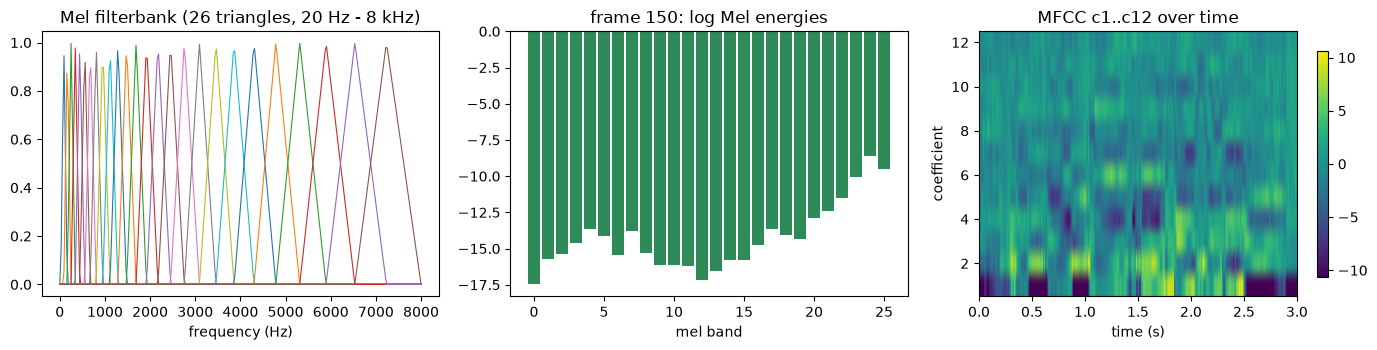

In [4]:
mfcc_f, mfcc_info = fx.extract_mfcc(sig, sr)
print(f"MFCC matrix : {mfcc_f.shape}  (frames x {fx.N_MFCC} coefficients)")
print(f"value range : {mfcc_f.min():.2f} .. {mfcc_f.max():.2f}  (c0 = energy term)")
print(f"steps       : pre-emphasis -> Hamming -> {fx.N_FFT}-point FFT power -> {fx.N_MELS} Mel filters "
      f"-> log -> DCT-II -> keep c0..c{fx.N_MFCC - 1}")

i = 150
lo, hi = np.percentile(mfcc_f[:, 1:], [2, 98])
lim = max(abs(lo), abs(hi))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(FREQS, mfcc_info["filters"].T, lw=0.8)
axes[0].set(xlabel="frequency (Hz)", title=f"Mel filterbank ({fx.N_MELS} triangles, 20 Hz - 8 kHz)")
axes[1].bar(np.arange(fx.N_MELS), mfcc_info["log_mel"][i], color="seagreen")
axes[1].set(xlabel="mel band", title=f"frame {i}: log Mel energies")
im = axes[2].imshow(mfcc_f[:, 1:].T, origin="lower", aspect="auto", cmap="viridis",
                    vmin=-lim, vmax=lim, extent=[0, len(sig) / sr, 0.5, fx.N_MFCC - 0.5])
axes[2].set(xlabel="time (s)", ylabel="coefficient", title="MFCC c1..c12 over time")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.tight_layout()
fig.savefig(OUT_DIR / "mfcc.png", dpi=130)
plt.show()

## Task 4 - PLP (perceptual linear prediction)

PLP (Hermansky, 1990) models **auditory processing** before the all-pole fit:

1. **Bark critical-band integration** - 21 triangular bands on the Bark scale
   `bark(f) = 13 atan(0.00076 f) + 3.5 atan((f/7500)^2)` approximate the cochlea's frequency resolution.
2. **Equal-loudness pre-emphasis** - the `E(f)` curve de-emphasises frequencies the ear hears less well.
3. **Intensity-to-loudness compression** - cube root `(.)^0.33` replaces the log, as in loudness perception.
4. **IDFT -> autocorrelation -> LPC (order 5)** - a low-order all-pole model of the auditory spectrum.
5. **Cepstral recursion** - transform the LPC coefficients into 13 cepstral coefficients.

PLP matrix  : (298, 13)  (frames x 13 cepstral coefficients)
value range : -4.14 .. 0.41
steps       : power spectrum -> equal-loudness E(f) -> 21 Bark bands -> cube root -> IDFT -> LPC order 5 (Levinson-Durbin) -> cepstral recursion


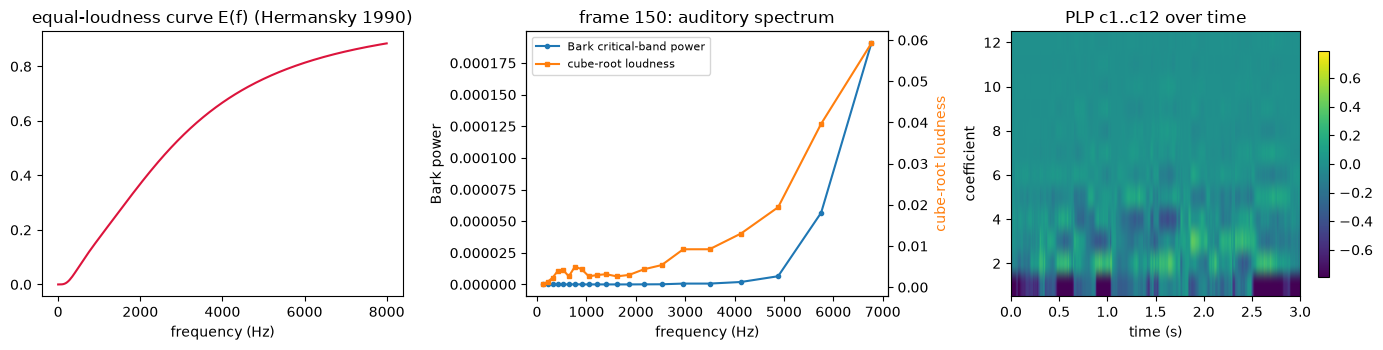

In [5]:
plp_f, plp_info = fx.extract_plp(sig, sr)
print(f"PLP matrix  : {plp_f.shape}  (frames x {fx.N_CEP} cepstral coefficients)")
print(f"value range : {plp_f.min():.2f} .. {plp_f.max():.2f}")
print(f"steps       : power spectrum -> equal-loudness E(f) -> {fx.N_BARK} Bark bands -> cube root "
      f"-> IDFT -> LPC order {fx.PLP_ORDER} (Levinson-Durbin) -> cepstral recursion")

edges = np.linspace(fx.hz_to_bark(20), fx.hz_to_bark(sr / 2), fx.N_BARK + 2)
centers = fx.bark_to_hz(edges[1:-1])
i = 150
lo, hi = np.percentile(plp_f[:, 1:], [2, 98])
lim = max(abs(lo), abs(hi))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(FREQS, plp_info["eq_curve"], color="crimson")
axes[0].set(xlabel="frequency (Hz)", title="equal-loudness curve E(f) (Hermansky 1990)")
ax_b = axes[1].twinx()
axes[1].plot(centers, plp_info["bark_spec"][i], "o-", ms=3, color="tab:blue", label="Bark critical-band power")
ax_b.plot(centers, plp_info["loudness"][i], "s-", ms=3, color="tab:orange", label="cube-root loudness")
axes[1].set(xlabel="frequency (Hz)", ylabel="Bark power", title=f"frame {i}: auditory spectrum")
ax_b.set_ylabel("cube-root loudness", color="tab:orange")
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax_b.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=8, loc="upper left")
im = axes[2].imshow(plp_f[:, 1:].T, origin="lower", aspect="auto", cmap="viridis",
                    vmin=-lim, vmax=lim, extent=[0, len(sig) / sr, 0.5, fx.N_CEP - 0.5])
axes[2].set(xlabel="time (s)", ylabel="coefficient", title="PLP c1..c12 over time")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.tight_layout()
fig.savefig(OUT_DIR / "plp.png", dpi=130)
plt.show()

## Task 5 - LPC coefficients and LPCC

**Linear prediction** models each sample as a weighted sum of the previous `p` samples;
the coefficients come from the autocorrelation normal equations solved with the
**Levinson-Durbin recursion** (order 12 here). The LPC spectrum `1/A(z)` is a smooth envelope of
the FFT spectrum, and its poles (all inside the unit circle for a stable fit) correspond to formants.
The **LPCC** are obtained with the cepstral recursion
`c1 = -a1`, `c_m = -a_m - sum_{k=1}^{m-1} (k/m) c_k a_{m-k}`, with `c0 = log(G)` from the gain.

LPCC matrix : (298, 13)
example frame 150: a1..a5 = [ 1.213  0.354 -0.547 -0.6   -0.614]   (order 12, residual 2.46e-07)
mean residual over all frames: 1.07e-04


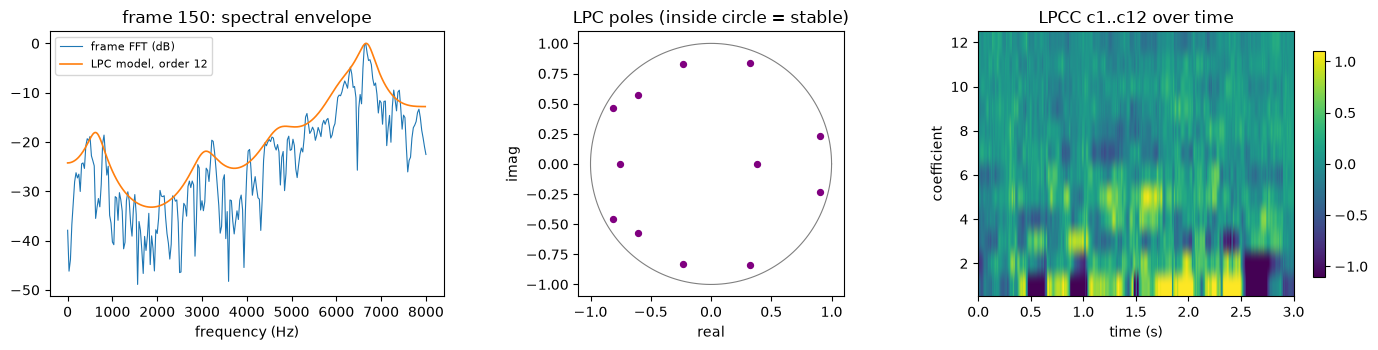

In [6]:
lpcc_f, lpcc_info = fx.extract_lpcc(sig, sr)
i = 150
a = lpcc_info["lpc"][i]
err = lpcc_info["errors"][i]
w, lpc_db = fx.lpc_spectrum(a, sr)
frame_power = fx.power_spectrum(lpcc_info["windowed"][i:i + 1], fx.N_FFT)[0]
fft_db = 10 * np.log10(np.maximum(frame_power / frame_power.max(), 1e-6))
lpc_db = lpc_db - np.max(lpc_db) + np.max(fft_db)
print(f"LPCC matrix : {lpcc_f.shape}")
print(f"example frame {i}: a1..a5 = {np.array2string(a[1:6], precision=3)}   (order {fx.LPC_ORDER}, residual {err:.2e})")
print(f"mean residual over all frames: {lpcc_info['errors'].mean():.2e}")

lo, hi = np.percentile(lpcc_f[:, 1:], [2, 98])
lim = max(abs(lo), abs(hi))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(FREQS, fft_db, lw=0.8, label="frame FFT (dB)")
axes[0].plot(w, lpc_db, lw=1.2, label=f"LPC model, order {fx.LPC_ORDER}")
axes[0].set(xlabel="frequency (Hz)", title=f"frame {i}: spectral envelope")
axes[0].legend(fontsize=8)
poles = np.roots(a)
theta = np.linspace(0, 2 * np.pi, 200)
axes[1].plot(np.cos(theta), np.sin(theta), lw=0.8, color="gray")
axes[1].scatter(poles.real, poles.imag, s=18, color="purple")
axes[1].set(xlabel="real", ylabel="imag", aspect="equal", title="LPC poles (inside circle = stable)")
im = axes[2].imshow(lpcc_f[:, 1:].T, origin="lower", aspect="auto", cmap="viridis",
                    vmin=-lim, vmax=lim, extent=[0, len(sig) / sr, 0.5, fx.N_CEP - 0.5])
axes[2].set(xlabel="time (s)", ylabel="coefficient", title="LPCC c1..c12 over time")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.tight_layout()
fig.savefig(OUT_DIR / "lpcc.png", dpi=130)
plt.show()

## Task 6 - GFCC (gammatone frequency cepstral coefficients)

The **gammatone filterbank** mimics the cochlea with 32 filters whose centre frequencies are equally
spaced on the **ERB scale**; each magnitude response is
`|H(f)| = (1 + ((f-fc)/b)^2)^(-2)` with `b = 1.019 ERB(fc)` (4th-order gammatone).
Filter energies are compressed with the **cube root** (cochlear compression, unlike MFCC's log)
and decorrelated with the DCT.

GFCC matrix : (298, 13)
value range : -41.49 .. 4.40
steps       : power spectrum -> 32 gammatone filters (ERB, 4th order) -> cube-root compression -> log -> DCT-II -> 13 coefficients


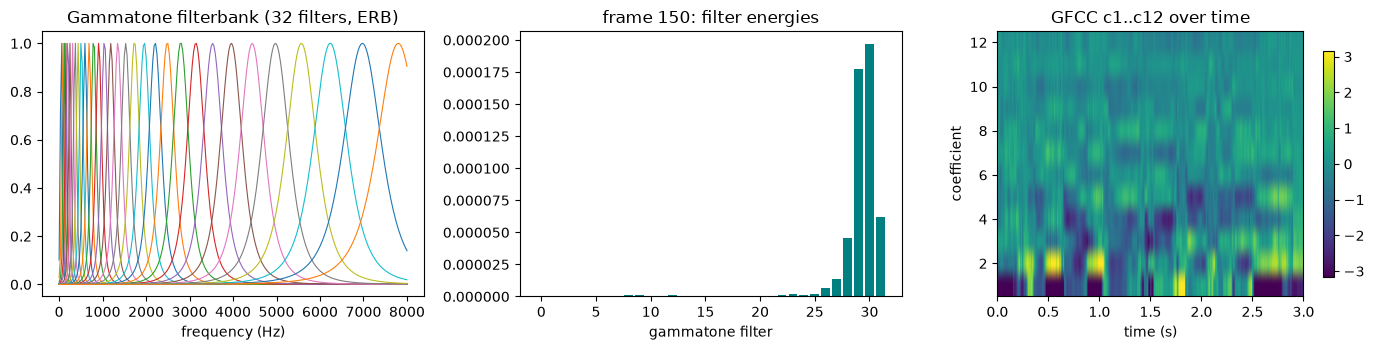

In [7]:
gfcc_f, gfcc_info = fx.extract_gfcc(sig, sr)
print(f"GFCC matrix : {gfcc_f.shape}")
print(f"value range : {gfcc_f.min():.2f} .. {gfcc_f.max():.2f}")
print(f"steps       : power spectrum -> {fx.N_GAMMATONE} gammatone filters (ERB, 4th order) "
      f"-> cube-root compression -> log -> DCT-II -> {fx.N_CEP} coefficients")

i = 150
lo, hi = np.percentile(gfcc_f[:, 1:], [2, 98])
lim = max(abs(lo), abs(hi))
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(FREQS, gfcc_info["filters"].T, lw=0.8)
axes[0].set(xlabel="frequency (Hz)", title=f"Gammatone filterbank ({fx.N_GAMMATONE} filters, ERB)")
axes[1].bar(np.arange(fx.N_GAMMATONE), gfcc_info["energies"][i], color="teal")
axes[1].set(xlabel="gammatone filter", title=f"frame {i}: filter energies")
im = axes[2].imshow(gfcc_f[:, 1:].T, origin="lower", aspect="auto", cmap="viridis",
                    vmin=-lim, vmax=lim, extent=[0, len(sig) / sr, 0.5, fx.N_CEP - 0.5])
axes[2].set(xlabel="time (s)", ylabel="coefficient", title="GFCC c1..c12 over time")
fig.colorbar(im, ax=axes[2], shrink=0.85)
fig.tight_layout()
fig.savefig(OUT_DIR / "gfcc.png", dpi=130)
plt.show()

## Task 7 - Visualisation and comparison

The four representations side by side (c0 dropped: it is only frame energy and dominates the colour
scale). Look at the temporal patterns: MFCC/LPCC/GFCC show the formant structure as bright and dark
bands; PLP is smoother because its auditory spectrum is modelled by a low-order (5) all-pole filter.

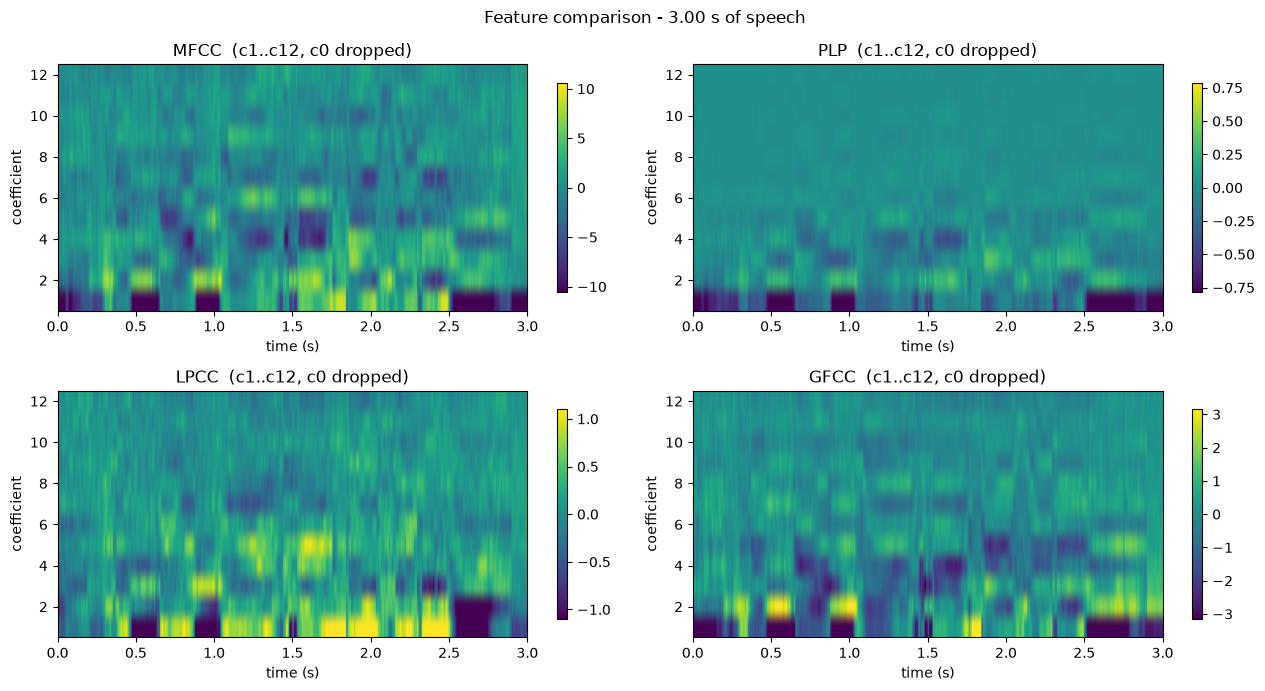

feature,frames,dims,mean |value|,mean temporal std,dynamic range
MFCC,298,13,6.136,3.945,127.256
PLP,298,13,0.230,0.134,4.549
LPCC,298,13,0.699,0.428,13.729
GFCC,298,13,2.058,1.299,45.888


saved: U:\VITc\speech lab\notebooks\lab8_outputs\feature_stats.csv


In [8]:
feats = {"MFCC": mfcc_f, "PLP": plp_f, "LPCC": lpcc_f, "GFCC": gfcc_f}
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (name, feat) in zip(axes.ravel(), feats.items()):
    show = feat[:, 1:].T
    lo, hi = np.percentile(show, [2, 98])
    lim = max(abs(lo), abs(hi))
    im = ax.imshow(show, origin="lower", aspect="auto", cmap="viridis",
                   vmin=-lim, vmax=lim, extent=[0, len(sig) / sr, 0.5, feat.shape[1] - 0.5])
    ax.set(xlabel="time (s)", ylabel="coefficient", title=f"{name}  (c1..c12, c0 dropped)")
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.suptitle(f"Feature comparison - {len(sig) / sr:.2f} s of speech")
fig.tight_layout()
fig.savefig(OUT_DIR / "feature_comparison.png", dpi=130)
plt.show()

stats = [fx.feature_stats(n, f) for n, f in feats.items()]
display(html_table(["feature", "frames", "dims", "mean |value|", "mean temporal std", "dynamic range"],
                   [[s["feature"], s["n_frames"], s["n_dims"], s["mean_abs"], s["temporal_std"],
                     s["dynamic_range"]] for s in stats]))
with open(OUT_DIR / "feature_stats.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(stats[0].keys()))
    w.writeheader()
    w.writerows(stats)
print("saved:", OUT_DIR / "feature_stats.csv")

## Task 8 - Suitability for speech recognition

What makes a feature good for a recogniser? It should be **compact**, **decorrelated** and
**stable when the signal is degraded**. The experiment below adds **white Gaussian noise** at
20 / 10 / 0 dB SNR to the clean segment, re-extracts all four features and measures the **per-frame
cosine similarity** between the clean and noisy vectors (coefficients c1..c12). Similarity 1.0 means
the feature vector is unchanged by noise; low similarity means the recogniser's input distribution
shifts.

per-frame cosine similarity, clean vs noisy (coefficients c1..c12):


feature,dims,SNR 20 dB,SNR 10 dB,SNR 0 dB
MFCC,13,0.803,0.600,0.348
PLP,13,0.882,0.797,0.706
LPCC,13,0.759,0.585,0.343
GFCC,13,0.800,0.607,0.411


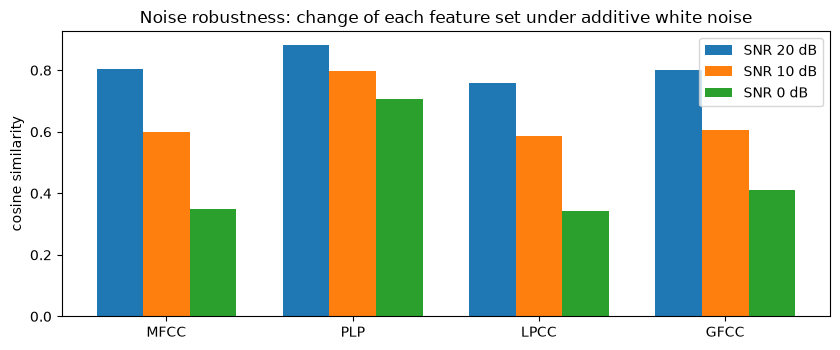

saved: U:\VITc\speech lab\notebooks\lab8_outputs\robustness.csv


In [9]:
SNRS = [20, 10, 0]
rng = np.random.default_rng(0)
extractors = {"MFCC": fx.extract_mfcc, "PLP": fx.extract_plp, "LPCC": fx.extract_lpcc, "GFCC": fx.extract_gfcc}
clean = {"MFCC": mfcc_f, "PLP": plp_f, "LPCC": lpcc_f, "GFCC": gfcc_f}

rows, sims = [], {}
for name, fn in extractors.items():
    sims[name] = []
    for snr_db in SNRS:
        noisy = fx.add_white_noise(sig, snr_db, rng)
        noisy_f, _ = fn(noisy, sr)
        n = min(len(clean[name]), len(noisy_f))
        sims[name].append(fx.frame_cosine(clean[name][:n], noisy_f[:n]))
    rows.append([name, clean[name].shape[1], *sims[name]])
print("per-frame cosine similarity, clean vs noisy (coefficients c1..c12):")
display(html_table(["feature", "dims", "SNR 20 dB", "SNR 10 dB", "SNR 0 dB"], rows))

x = np.arange(len(extractors))
width = 0.25
fig, ax = plt.subplots(figsize=(8.5, 3.6))
for k, snr_db in enumerate(SNRS):
    ax.bar(x + (k - 1) * width, [sims[n][k] for n in extractors], width, label=f"SNR {snr_db} dB")
ax.set_xticks(x)
ax.set_xticklabels(list(extractors))
ax.set_ylabel("cosine similarity")
ax.set_title("Noise robustness: change of each feature set under additive white noise")
ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / "robustness.png", dpi=130)
plt.show()

with open(OUT_DIR / "robustness.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.writer(f)
    w.writerow(["feature", "dims"] + [f"snr_{s}db" for s in SNRS])
    w.writerows(rows)
print("saved:", OUT_DIR / "robustness.csv")

## Notes / what to look for

Numbers are from the reference run of this notebook (3 s of `harvard.wav`, 16 kHz, 298 frames,
seed 0).

- **MFCC (Task 3):** 13 coefficients per 10 ms frame. c0 is the frame energy and swings over a
  range of about 127 units, while c1..c12 stay within about +/-10 - one reason a recogniser
  usually normalses or drops c0.
- **PLP (Task 4):** the equal-loudness curve de-emphasises everything below about 1 kHz; after
  Bark integration and cube-root compression the values are tiny (range -4.1 .. 0.4). The twin
  axis in the figure shows why: the cube root squeezes a Bark power range of five orders of
  magnitude (1e-7 .. 1e-4) into roughly one decade (0.005 .. 0.06). Because the auditory spectrum
  is smoothed twice (critical bands, then a low-order all-pole model), the PLP heatmap is visibly
  blurrier than the others.
- **LPCC (Task 5):** the order-12 LPC envelope follows the frame's FFT spectrum closely, all poles
  sit inside the unit circle (stable filter) and the mean prediction error is ~1e-4.
- **GFCC (Task 6):** the ERB spacing puts most of the 32 gammatone filters below 2 kHz. Cube-root
  compression (instead of log) keeps the coefficient range wide for the energy term (-41 .. 4)
  but stable for c1..c12.
- **Comparison (Task 7):** all four representations react to the same events (the dark columns at
  the sentence/stop boundaries around 0.55 s, 1.0 s and 2.55 s), at different sharpness. Mean
  |value| / temporal std: MFCC 6.14 / 3.95, GFCC 2.06 / 1.30, LPCC 0.70 / 0.43, PLP 0.23 / 0.13.
- **Robustness (Task 8):** cosine similarity between clean and noisy frames (c1..c12), white
  Gaussian noise:

| SNR | MFCC | PLP | LPCC | GFCC |
|---|---|---|---|---|
| 20 dB | 0.803 | **0.882** | 0.759 | 0.800 |
| 10 dB | 0.600 | **0.797** | 0.585 | 0.607 |
| 0 dB | 0.348 | **0.706** | 0.343 | 0.411 |

  PLP is clearly the most stable - at 0 dB it still scores 0.71 while the others drop below 0.45.
  That is exactly what its design predicts: equal-loudness weighting and cube-root loudness
  compression suppress the low-level detail that noise dominates. GFCC keeps a small edge over
  MFCC/LPCC at 0 dB (0.41 vs 0.35/0.34), consistent with the cochlear compression used in the
  GFCC literature. LPCC is the least robust - it is a pure all-pole fit of the *noisy*
  autocorrelation, with no auditory weighting.
- **Suitability for ASR:** MFCC is the standard choice - compact, decorrelated, strong on clean
  speech; PLP is preferable when training and test conditions differ (channel/noise mismatch),
  which the table already shows at 20 dB; LPCC is very compact and works well for voiced segments
  (classic HMM systems); GFCC is the best of the four under heavy noise. In modern systems this
  front-end (MFCC or log-Mel + CMVN) is often replaced by learned features - Lab 9 shows a CNN
  classifying directly from log-Mel images.
- The experiment uses one clean signal, one noise seed and cosine similarity; changing the
  segment or seed moves the absolute numbers by a few points, but the ordering (PLP most robust)
  is stable across runs because it follows from the algorithm, not from luck.

## Running the solution as a script

The same analysis is available from the command line:

```powershell
cd "lab 8\solution"
python feature_extraction.py                       # harvard.wav segment, 3 s
python feature_extraction.py --synthetic           # built-in /a-i-u/ utterance (offline demo)
python feature_extraction.py --wav my.wav --start 0.5 --duration 4.0 --snr 5
```

The script prints the same eight tasks and writes `results/feature_comparison.png`,
`results/filterbanks.png`, `results/feature_stats.csv` and `results/robustness.csv`.